# Набор данных о качестве вина

- Предметная область: Виноделие, оценка качества красного вина.
- Источник: https://www.kaggle.com/datasets/yasserh/wine-quality-dataset
- Тип данных: Реальные. Данные собраны для образцов португальского вина «Vinho Verde».

# Атрибуты
Датасет состоит только из числовых атрибутов - все они типа float, кроме оценки вина. Имеются следующие атрибуты:

| № | Признак | Тип | Описание |
| :--- | :--- | :--- | :--- |
| 1 | fixed acidity | Числовой | Фиксированная кислотность |
| 2 | volatile acidity | Числовой | Летучая кислотность |
| 3 | citric acid | Числовой | Лимонная кислота |
| 4 | residual sugar | Числовой | Остаточный сахар |
| 5 | chlorides | Числовой | Хлориды |
| 6 | free sulfur dioxide | Числовой | Свободный диоксид серы |
| 7 | total sulfur dioxide | Числовой | Общий диоксид серы |
| 8 | density | Числовой | Плотность |
| 9 | pH | Числовой | Кислотность |
| 10 | sulphates | Числовой | Сульфаты |
| 11 | alcohol | Числовой | Содержание алкоголя |
| 12 | **quality** | **Числовой (целевой)** | **Оценка качества (0–10)** |


# Набор применим для:
- Регрессии: предсказать числовое значение quality; 
- Кластеризации: Разбить вина на группы по химическому составу;
- Классификации: Предсказать категорию качества (плохое/среднее/хорошее).

### Автор указал задачу классификации:
- Классификация: Предсказание качества вина на основе физико-химических свойств.

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
df = pd.read_csv('datasets/WineQT.csv')
df = df.drop('Id', axis=1)
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [28]:
df.info()
print("Размер датасета:", df.shape)
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 107.3 KB
Размер датасета: (1143, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000,1143.000000
mean,8.311111,0.531339,0.268364,2.532152,0.086933,15.615486,45.914698,0.996730,3.311015,0.657708,10.442111,5.657043
std,1.747595,0.179633,0.196686,1.355917,0.047267,10.250486,32.782130,0.001925,0.156664,0.170399,1.082196,0.805824
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.392500,0.090000,1.900000,0.070000,7.000000,21.000000,0.995570,3.205000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.250000,2.200000,0.079000,13.000000,37.000000,0.996680,3.310000,0.620000,10.200000,6.000000
75%,9.100000,0.640000,0.420000,2.600000,0.090000,21.000000,61.000000,0.997845,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,68.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


# Пропущенные значения:

In [29]:
df.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

В датасете отсутствуют пропущенные значения - все 1143 записи содержат полные данные по каждому из 12 признаков.


# Среднее значение + СКО:

In [30]:
stats = pd.DataFrame({
    'Среднее': df.mean(),
    'СКО': df.std()
})
stats.round(4)

,Среднее,СКО
fixed acidity,8.3111,1.7476
volatile acidity,0.5313,0.1796
citric acid,0.2684,0.1967
residual sugar,2.5322,1.3559
chlorides,0.0869,0.0473
free sulfur dioxide,15.6155,10.2505
total sulfur dioxide,45.9147,32.7821
density,0.9967,0.0019
pH,3.3110,0.1567
sulphates,0.6577,0.1704


# Гистограмма распределений значений:

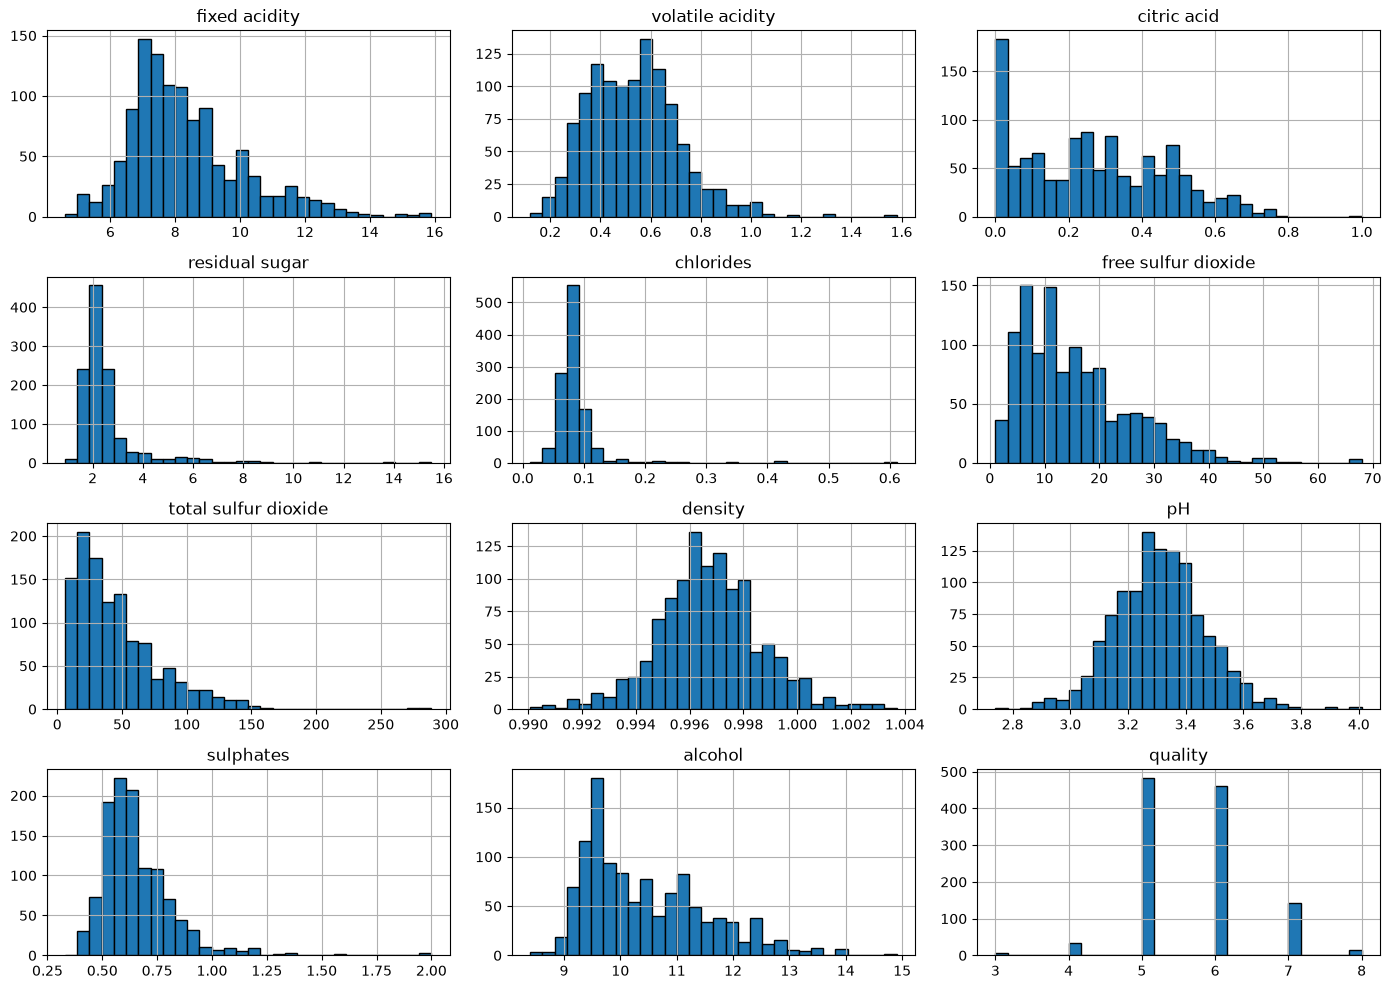

In [35]:
df.hist(figsize=(14, 10), bins=30, edgecolor='black')
plt.tight_layout()
plt.show()

# Выбросы:

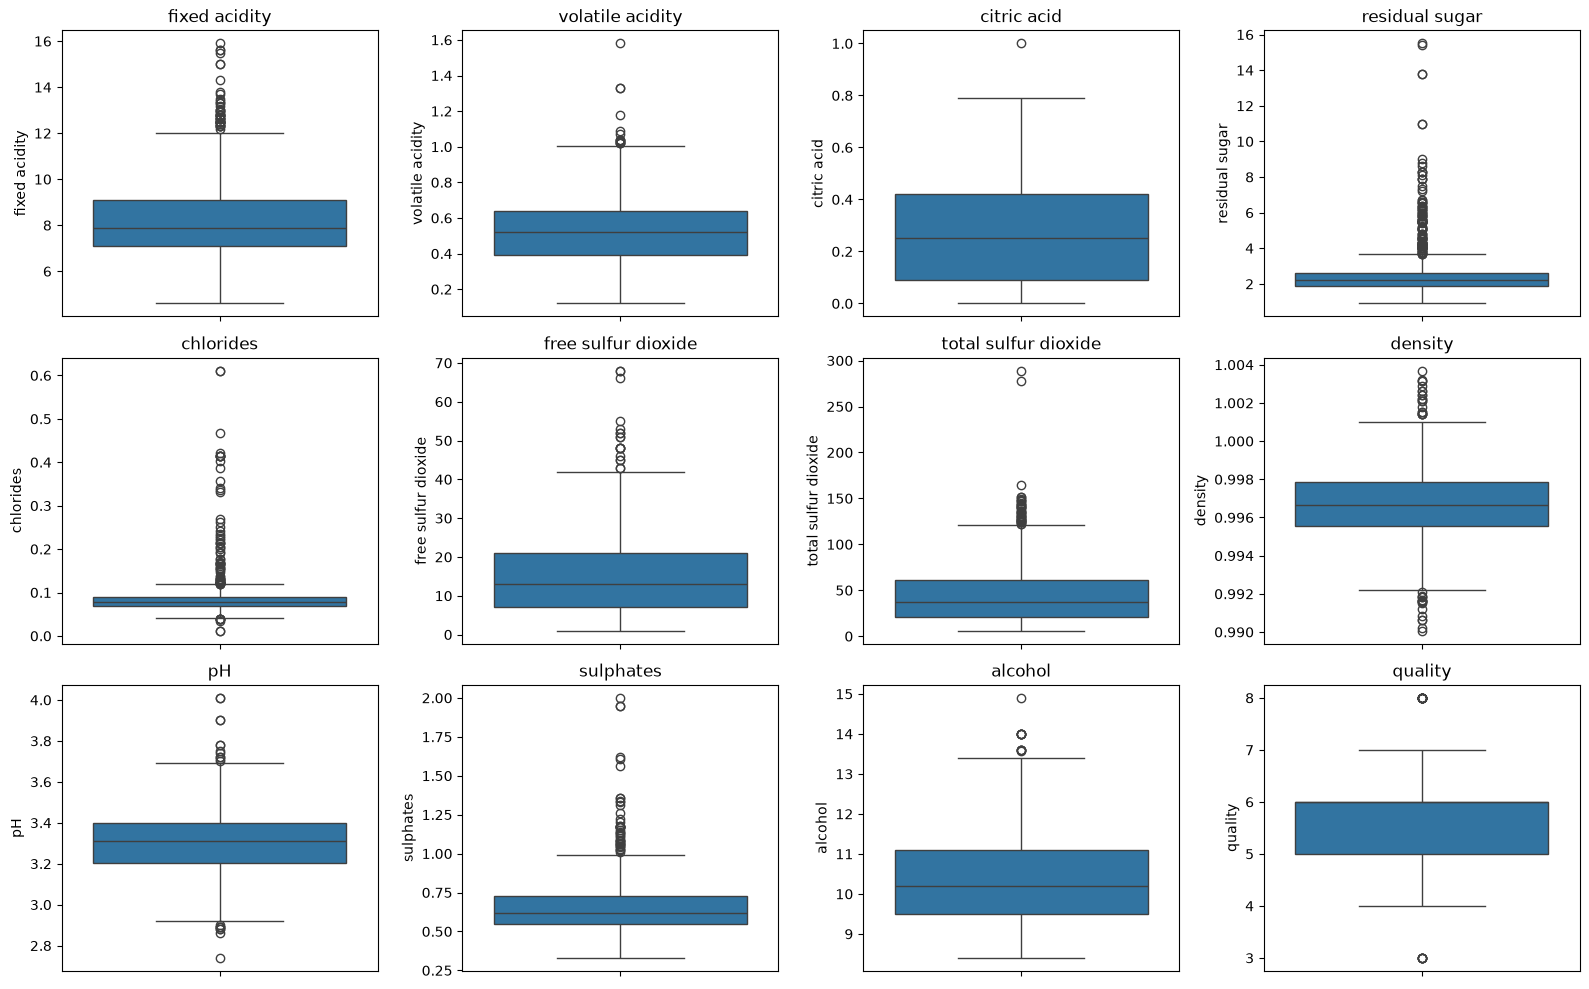

In [32]:
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 10))
axes = axes.flatten()
for i, col in enumerate(df.columns):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(col)
plt.tight_layout()
plt.show()

По диаграммам размаха видно, что выбросы присутствуют в большинстве признаков.

# Корреляция:

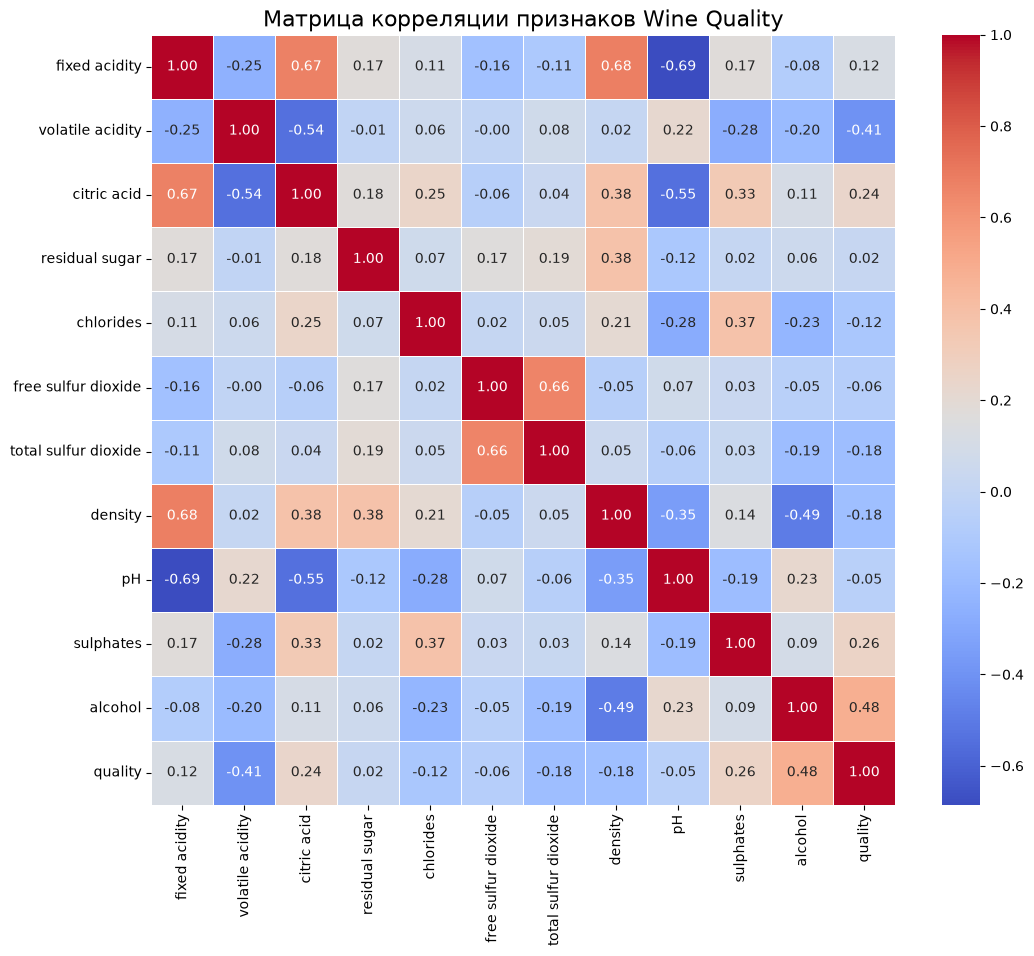

In [33]:
plt.figure(figsize=(12, 10))
corr = df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Матрица корреляции признаков Wine Quality', fontsize=16)
plt.show()

**Сильная корреляция (|r| >= 0.70):**
В данном датасете сильных корреляций не обнаружено. 
Максимальная корреляция составляет 0.68 (fixed acidity и density).

**Умеренная корреляция (0.30 < |r| < 0.70):**
- pH и fixed acidity — обратная (r = -0.69)
- density и fixed acidity — прямая (r = 0.68)
- citric acid и fixed acidity — прямая (r = 0.67)
- pH и citric acid — обратная (r = -0.55)
- citric acid и volatile acidity — обратная (r = -0.54)
- density и citric acid — прямая (r = 0.38)
- sulphates и citric acid — прямая (r = 0.33)
- alcohol и density — обратная (r = -0.49)
- density и residual sugar — прямая (r = 0.38)
- pH и density — обратная (r = -0.35)
- quality и alcohol — прямая (r = 0.48)
- quality и volatile acidity — обратная (r = -0.41)
- sulphates и chlorides — прямая (r = 0.37)
  
**Остальные атрибуты имеют слабую корреляцию или не имеют корреляции вообще.**


# Графики рассеиания:

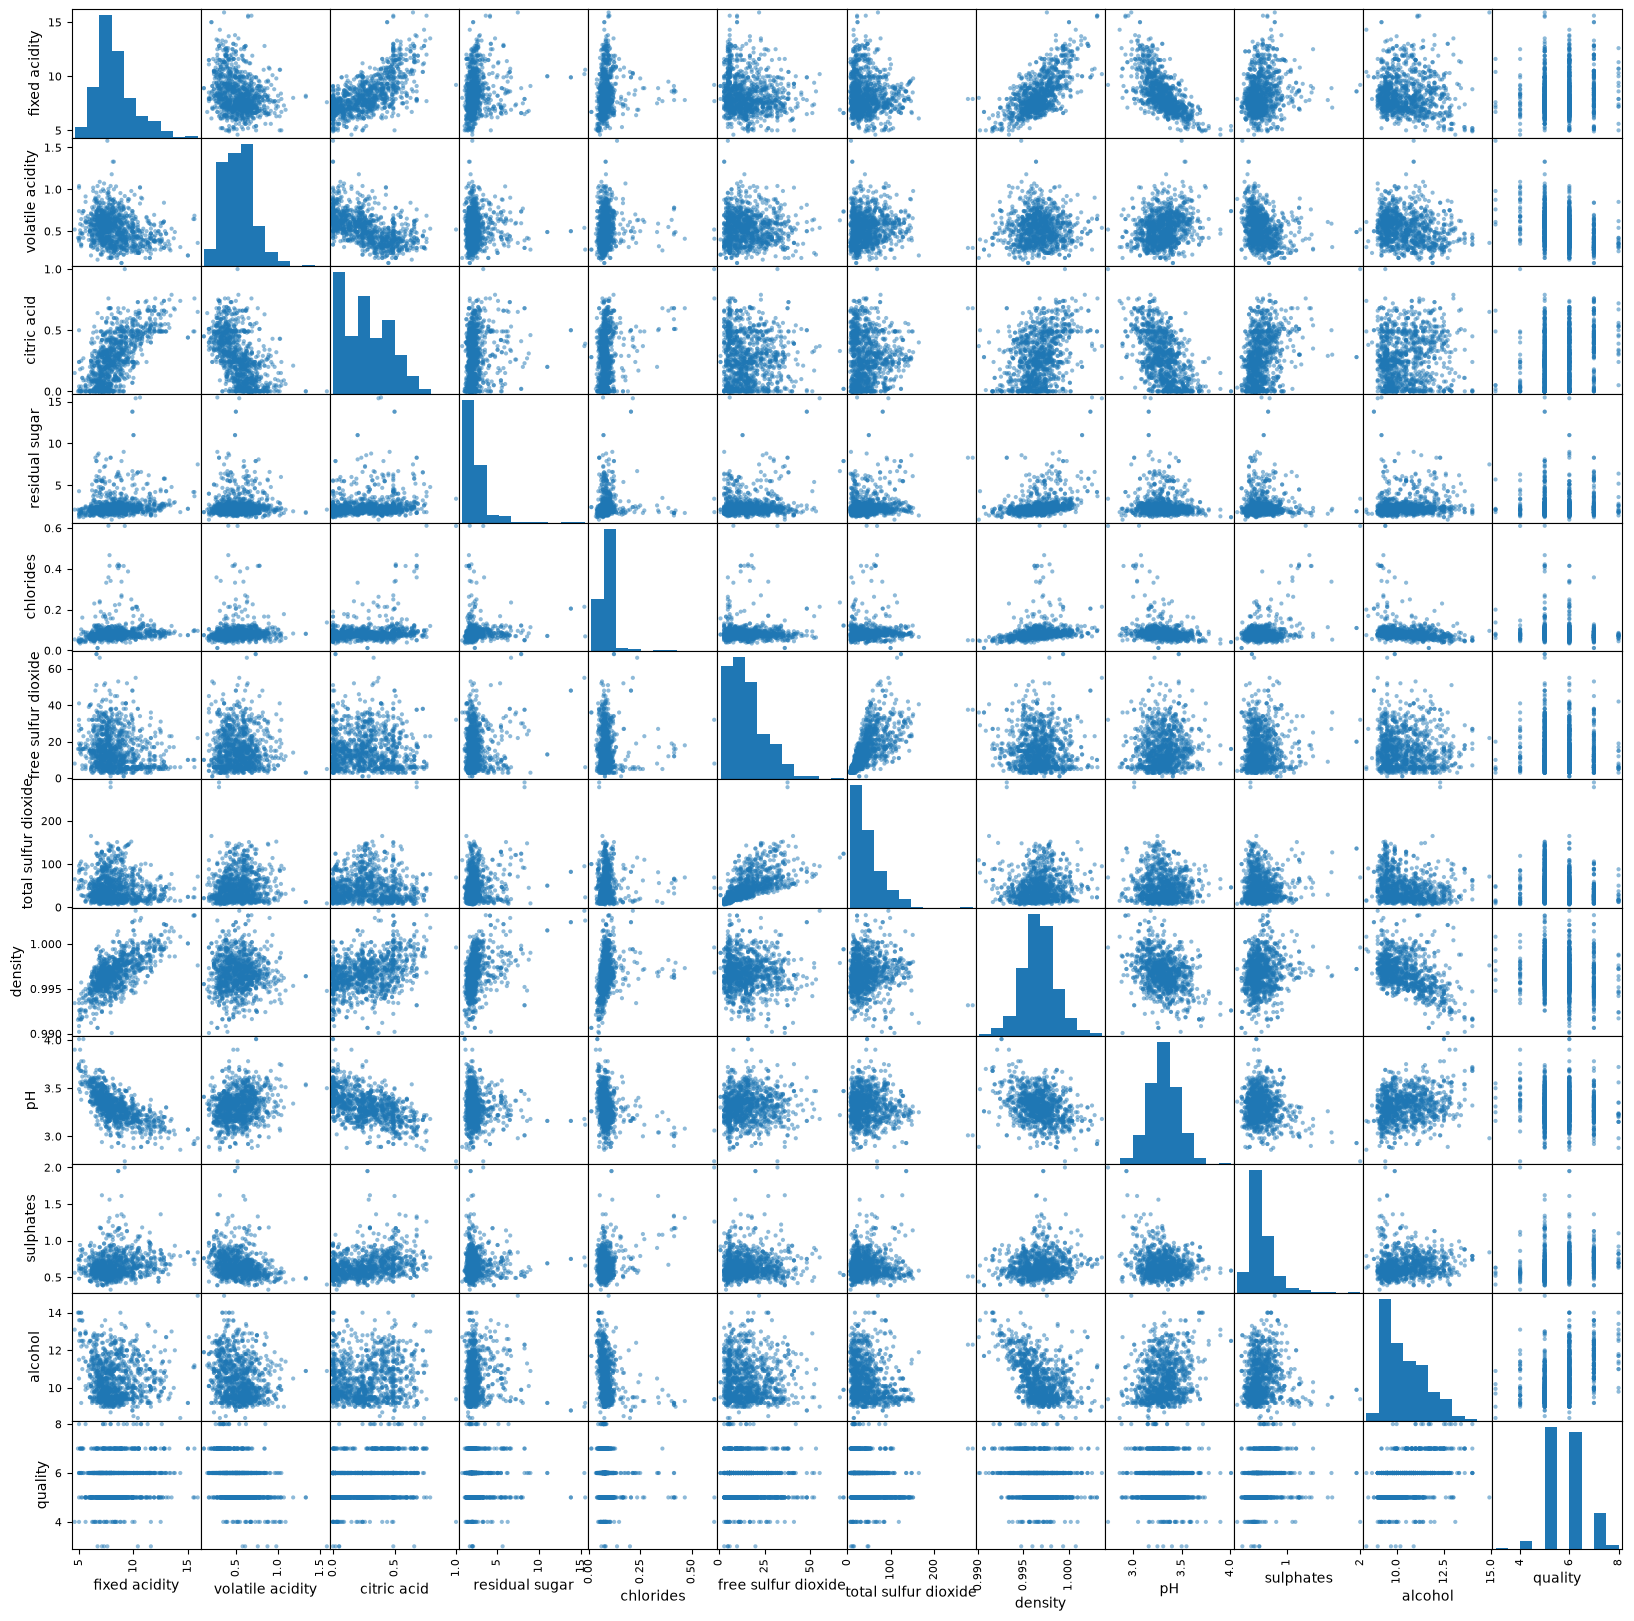

In [34]:
mat = pd.plotting.scatter_matrix(df, figsize=(20,20))

- alcohol и quality — положительная тенденция: с ростом алкоголя оценка качества увеличивается.

- volatile acidity и quality — обратная тенденция: с ростом летучей кислоты качество снижается.

- fixed acidity и pH — чёткая обратная линейная зависимость.

- fixed acidity и citric acid — прямая линейная зависимость.

- Для прямых корреляций облако точек вытянуто вдоль прямой с положительным наклоном (k > 0): с ростом x растёт y.
- Для обратных корреляций облако точек вытянуто вдоль прямой с отрицательным наклоном (k < 0): с ростом x падает y.
- Чем плотнее облако вокруг воображаемой прямой, тем сильнее связь.